# Error analysis and robustness #
Material for the report section *Error Analysis and Robustness*. Combines the saved test forecasts of every model that
has been run (`xgboost.ipynb`, `neural_network.ipynb`, `lstm.ipynb`, `local_vs_global.ipynb`) on the same 10,495 test
hours and breaks the errors down by price area, hour, week, temperature and over time. *Local heads* are the
CNN's convolutions with one dense head per location (see `local_vs_global.ipynb`); its global variant is the
*CNN* itself. Feature importance and temperature-noise sensitivity are computed in the model notebooks (they
need the trained models) and only plotted here. The test period (20 Jan - 3 Apr 2023) has no public holidays, so
holidays are scored on the validation windows (4 Dec - 14 Jan).

Figures are saved to `figures/` as PDF for `\includegraphics`.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, "../machine_learning")
from forecast_checks import ForecastValidator, MakeTrainingData, load_tables

RESULTS, FIGURES = Path("../machine_learning/results"), Path("figures")
FIGURES.mkdir(exist_ok=True)
MODELS = {"XGBoost": "xgboost", "CNN": "neural_network", "LSTM": "lstm", "Local heads": "local_vs_global"}
SAVED_AS = {"CNN": "Neural network"}   #name neural_network.ipynb saved the forecast under
AREAS = {"oslo": "NO1 Oslo", "stavanger": "NO2 Stavanger", "trondheim": "NO3 Trondheim", "tromsø": "NO4 Tromsø",
         "bergen": "NO5 Bergen", "helsingfors": "FI Helsingfors"}


def combine(suffix: str) -> ForecastValidator:
    """One validator with the baseline and every model whose results/<model><suffix>.json exists."""
    paths = {name: RESULTS / f"{stem}{suffix}.json" for name, stem in MODELS.items()}
    missing = [name for name, path in paths.items() if not path.exists()]
    if missing:
        print(f"Not run yet, left out: {missing}")
    loaded = {name: ForecastValidator.load_predictions(path) for name, path in paths.items() if path.exists()}
    if not loaded:
        raise FileNotFoundError(f"No results/*{suffix}.json; run the model notebooks first")
    combined = next(iter(loaded.values()))
    for name, validator in loaded.items():
        if name not in combined.forecasts:
            combined.add(name, validator.forecasts[SAVED_AS.get(name, name)])   #add checks that the models were scored on the same hours
    #Other forecasts saved alongside (the global CNN in local_vs_global, the same forecast as the CNN) are left out
    combined.forecasts = {name: f for name, f in combined.forecasts.items() if name in MODELS or name == combined.baseline}
    combined.groups = combined.groups.map(AREAS).rename("Price area")
    return combined


test = combine("_predictions")
df = MakeTrainingData().df
info = df.loc[test.actual.index]
assert (info["location"].astype(str).map(AREAS) == test.groups).all()
print(f"{len(info)} test hours, {info['date'].min().date()} - {info['date'].max().date()}")
test.summary(skill=True)

10495 test hours, 2023-01-20 - 2023-04-03


,mae,rmse,nmae,bias,skill
Same hour last week,0.494720,0.806999,8.983281,0.033943,0.000000
XGBoost,0.338576,0.538403,6.147963,0.162479,0.315622
CNN,0.293915,0.435369,5.337004,0.179565,0.405896
LSTM,0.286146,0.418565,5.195926,-0.046909,0.421600
Local heads,0.289837,0.443618,5.262946,0.149883,0.414140


## Per price area (table) ##
MAE in MW, and nMAE (MAE in % of consumption) so areas of different size are comparable.

In [2]:
per_area = test.per_group()
overall = test.summary().rename_axis("model").assign(group="All").set_index("group", append=True)
per_area_table = pd.concat([per_area, overall])[["mae", "nmae"]].unstack("model").reindex([*AREAS.values(), "All"])
per_area_table = per_area_table.reindex(columns=list(test.forecasts), level="model")
per_area_table.round(2)

mae                                  \
model          Same hour last week XGBoost   CNN  LSTM Local heads   
group                                                                
NO1 Oslo                      1.30    0.87  0.71  0.62        0.73   
NO2 Stavanger                 0.59    0.48  0.32  0.37        0.34   
NO3 Trondheim                 0.41    0.22  0.20  0.25        0.20   
NO4 Tromsø                    0.18    0.10  0.11  0.09        0.12   
NO5 Bergen                    0.35    0.23  0.17  0.24        0.18   
FI Helsingfors                0.14    0.14  0.25  0.14        0.17   
All                           0.49    0.34  0.29  0.29        0.29   

                              nmae                                  
model          Same hour last week XGBoost   CNN  LSTM Local heads  
group                                                               
NO1 Oslo                     10.67    7.11  5.78  5.11        6.00  
NO2 Stavanger                10.51    8.51  5.72  6.60        6.10  
NO3 Trondheim                11.25    6.07  5.63  6.98        5.40  
NO4 Tromsø                    9.41    5.10  5.78  4.84        6.28  
NO5 Bergen                   10.77    7.05  5.27  7.35        5.46  
FI Helsingfors                2.12    2.13  3.89  2.14        2.64  
All                           8.98    6.15  5.34  5.20        5.26

In [3]:
print(per_area_table.to_latex(float_format="%.2f"))

\begin{tabular}{lrrrrrrrrrr}
\toprule
 & \multicolumn{5}{r}{mae} & \multicolumn{5}{r}{nmae} \\
model & Same hour last week & XGBoost & CNN & LSTM & Local heads & Same hour last week & XGBoost & CNN & LSTM & Local heads \\
group &  &  &  &  &  &  &  &  &  &  \\
\midrule
NO1 Oslo & 1.30 & 0.87 & 0.71 & 0.62 & 0.73 & 10.67 & 7.11 & 5.78 & 5.11 & 6.00 \\
NO2 Stavanger & 0.59 & 0.48 & 0.32 & 0.37 & 0.34 & 10.51 & 8.51 & 5.72 & 6.60 & 6.10 \\
NO3 Trondheim & 0.41 & 0.22 & 0.20 & 0.25 & 0.20 & 11.25 & 6.07 & 5.63 & 6.98 & 5.40 \\
NO4 Tromsø & 0.18 & 0.10 & 0.11 & 0.09 & 0.12 & 9.41 & 5.10 & 5.78 & 4.84 & 6.28 \\
NO5 Bergen & 0.35 & 0.23 & 0.17 & 0.24 & 0.18 & 10.77 & 7.05 & 5.27 & 7.35 & 5.46 \\
FI Helsingfors & 0.14 & 0.14 & 0.25 & 0.14 & 0.17 & 2.12 & 2.13 & 3.89 & 2.14 & 2.64 \\
All & 0.49 & 0.34 & 0.29 & 0.29 & 0.29 & 8.98 & 6.15 & 5.34 & 5.20 & 5.26 \\
\bottomrule
\end{tabular}



## By hour of day and by weekday ##
nMAE rather than MAE, so Oslo (about 6 times the consumption of Tromsø) does not dominate.

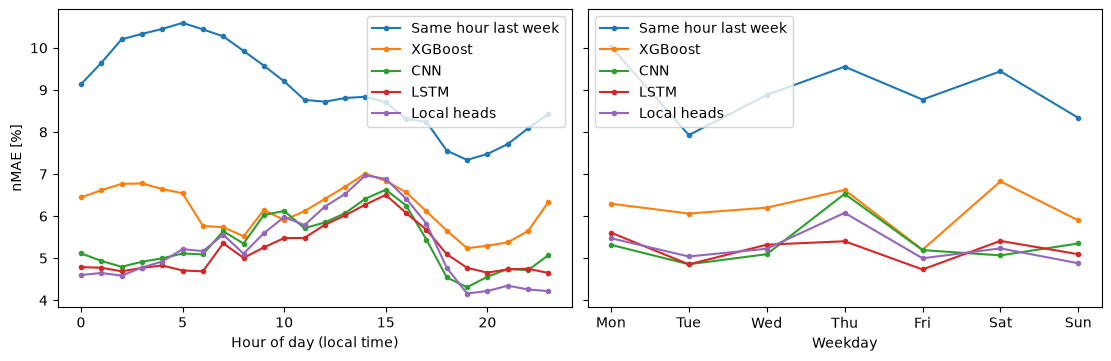

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True, layout="constrained")
test.plot_metric_by(info["hour"].rename("Hour of day (local time)"), ax=axes[0])
#From the local date, so it matches the local hour on the left. Ordered Monday - Sunday, not alphabetically
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday = pd.Series(pd.Categorical.from_codes(info["date"].dt.dayofweek, categories=DAYS), index=info.index,
                    name="Weekday")
test.plot_metric_by(weekday, ax=axes[1])
fig.savefig(FIGURES / "error_by_hour_and_weekday.pdf")

## Cold spells ##
Days are ranked by their mean temperature within each location (decile 1 = the coldest 10 % of test days there), so cold
spells in all areas are compared despite their different climates.

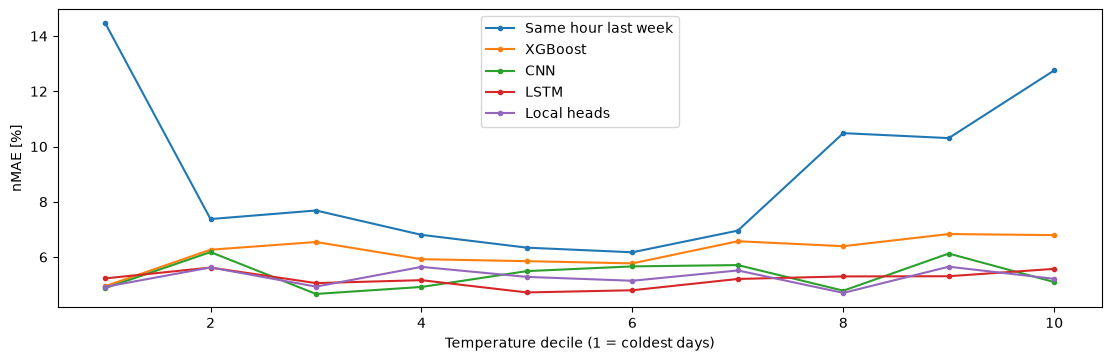

In [5]:
daily_temperature = info.groupby(["location", "date"], observed=True)["temperature"].transform("mean")
decile = (daily_temperature.groupby(info["location"], observed=True)
          .transform(lambda t: pd.qcut(t.rank(method="dense"), 10, labels=False) + 1)
          .rename("Temperature decile (1 = coldest days)"))
fig, axes = plt.subplots(1, 1, figsize=(11, 3.5), layout="constrained")
test.plot_metric_by(decile, ax=axes)
fig.savefig(FIGURES / "error_by_temperature.pdf")

In [6]:
cold_spell = (decile == 1).map({True: "Coldest 10 % of days", False: "Other days"}).rename("period")
test.per(cold_spell, skill=True)

mae      rmse       nmae  \
model               period                                                
Same hour last week Coldest 10 % of days  0.891356  1.314524  14.476407   
                    Other days            0.445815  0.720060   8.214823   
XGBoost             Coldest 10 % of days  0.304351  0.457774   4.942922   
                    Other days            0.342796  0.547522   6.316541   
CNN                 Coldest 10 % of days  0.299929  0.434010   4.871110   
                    Other days            0.293174  0.435536   5.402180   
LSTM                Coldest 10 % of days  0.321771  0.501127   5.225838   
                    Other days            0.281753  0.407227   5.191742   
Local heads         Coldest 10 % of days  0.302984  0.464382   4.920723   
                    Other days            0.288216  0.440990   5.310821   

                                              bias     skill  
model               period                                    
Same hour last week Coldest 10 % of days -0.880345  0.000000  
                    Other days            0.146675  0.000000  
XGBoost             Coldest 10 % of days  0.017276  0.658553  
                    Other days            0.180383  0.231080  
CNN                 Coldest 10 % of days  0.186316  0.663514  
                    Other days            0.178732  0.342386  
LSTM                Coldest 10 % of days -0.052946  0.639010  
                    Other days           -0.046165  0.368003  
Local heads         Coldest 10 % of days  0.185402  0.660087  
                    Other days            0.145503  0.353508

## Bias over time: portfolio level shifts ##
A curve that stays away from 0 for weeks means the level of the area has changed (e.g. customers gained or lost), which
consumption lags that are at least 6 days old cannot catch up with immediately.

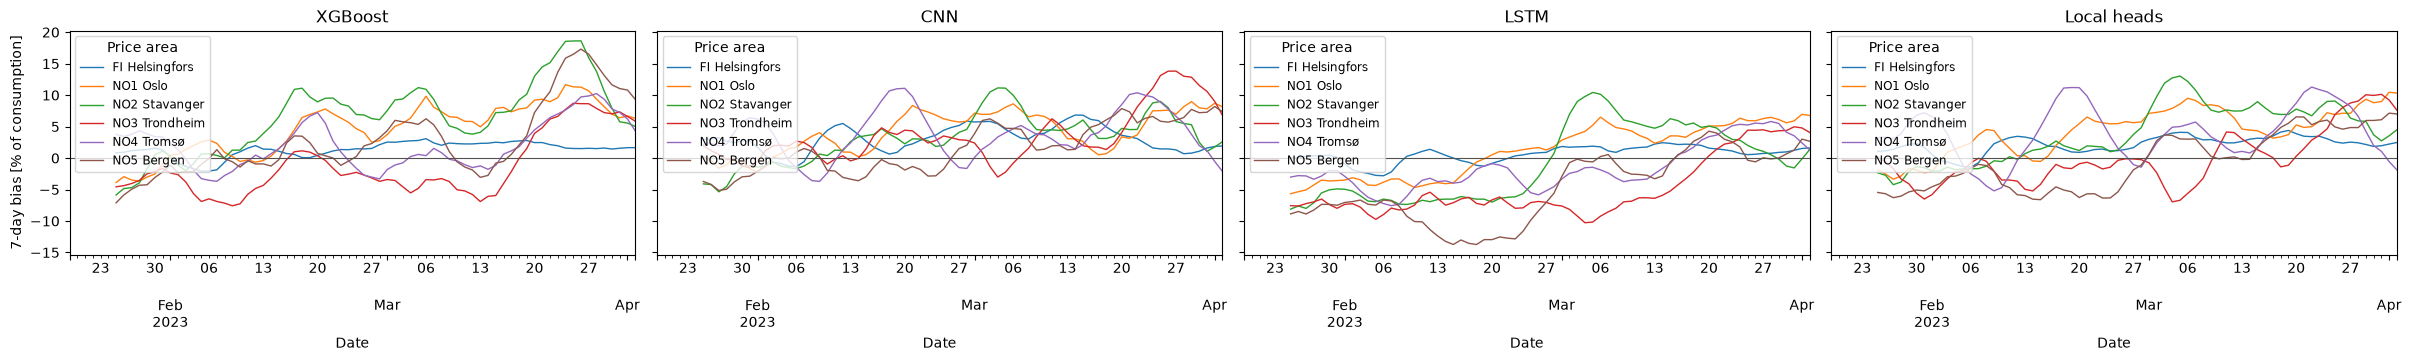

In [7]:
fig = test.plot_rolling_bias(info["time"])
fig.savefig(FIGURES / "rolling_bias.pdf")

## Feature importance and temperature forecast error ##
Left: increase in test MAE when a group of inputs is shuffled within each location. Right: increase in test MAE when a
day-ahead temperature forecast error with the given standard deviation is added (our temperature is reanalysis data,
i.e. close to the real weather).

XGBoost         CNN       LSTM
importance [%]        consumption    14.935389   94.326540  22.537975
                      temperature    57.184490  100.956032  83.370011
                      calendar       43.185721    9.087563  47.686680
                      other weather   0.302779    0.471590   1.086346
temperature noise [%] 0.0             0.000000    0.000000   0.000000
                      0.5             1.707192    0.981610   1.146111
                      1.0             4.065884    2.694059   3.648121
                      2.0            10.149197    7.439845  10.416684
                      3.0            15.246413   15.508737  23.222562

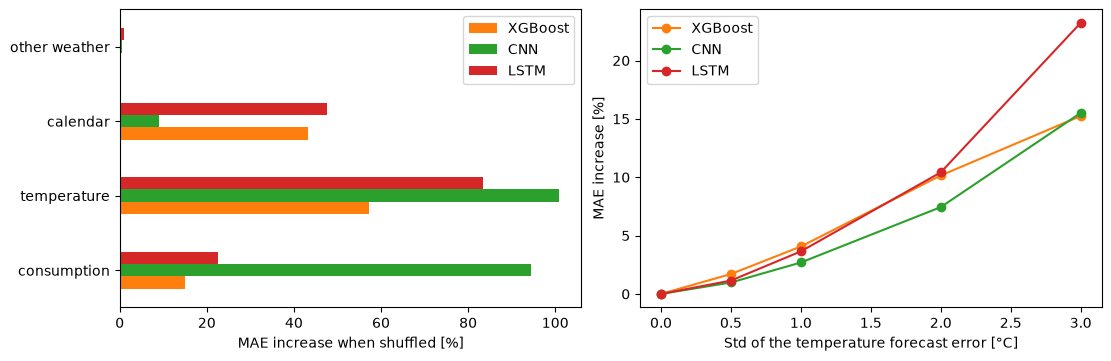

In [8]:
robustness = {name: load_tables(RESULTS / f"{stem}_robustness.json") for name, stem in MODELS.items()
              if (RESULTS / f"{stem}_robustness.json").exists()}
importance = pd.DataFrame({name: tables["importance"]["relative_increase"] for name, tables in robustness.items()})
temperature_noise = pd.DataFrame({name: tables["temperature_noise"]["relative_increase"] for name, tables in robustness.items()})

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
importance.plot.barh(ax=axes[0], color=test.colors(importance.columns))
axes[0].set_xlabel("MAE increase when shuffled [%]")
axes[0].set_ylabel("")
temperature_noise.plot(ax=axes[1], marker="o", color=test.colors(temperature_noise.columns))
axes[1].set_xlabel("Std of the temperature forecast error [°C]")
axes[1].set_ylabel("MAE increase [%]")
fig.savefig(FIGURES / "importance_and_temperature_noise.pdf")
pd.concat({"importance [%]": importance, "temperature noise [%]": temperature_noise})

## Holidays (validation windows) ##
The test period has no public holidays, so Christmas and New Year are scored on the validation windows (4 Dec - 14 Jan),
with each model fitted only on data up to 6 days before each window. Note that the CNN and the LSTM chose
their hyperparameters, and the local heads their number of epochs, on these windows, so their validation scores are
slightly optimistic compared with XGBoost's.

In [9]:
val = combine("_validation_predictions")
val_info = df.loc[val.actual.index]
CHRISTMAS = ("2022-12-24", "2023-01-01")
period = (val_info["date"].between(*CHRISTMAS)
          .map({True: "Christmas and New Year (24 Dec - 1 Jan)", False: "Other validation days"}).rename("period"))
val.per(period, skill=True)

mae  \
model               period                                              
Same hour last week Christmas and New Year (24 Dec - 1 Jan)  0.532187   
                    Other validation days                    0.838910   
XGBoost             Christmas and New Year (24 Dec - 1 Jan)  0.526465   
                    Other validation days                    0.609209   
CNN                 Christmas and New Year (24 Dec - 1 Jan)  0.315085   
                    Other validation days                    0.401591   
LSTM                Christmas and New Year (24 Dec - 1 Jan)  0.388400   
                    Other validation days                    0.399011   
Local heads         Christmas and New Year (24 Dec - 1 Jan)  0.394896   
                    Other validation days                    0.446031   

                                                                 rmse  \
model               period                                              
Same hour last week Christmas and New Year (24 Dec - 1 Jan)  0.881321   
                    Other validation days                    1.282444   
XGBoost             Christmas and New Year (24 Dec - 1 Jan)  0.808708   
                    Other validation days                    0.945923   
CNN                 Christmas and New Year (24 Dec - 1 Jan)  0.460125   
                    Other validation days                    0.616086   
LSTM                Christmas and New Year (24 Dec - 1 Jan)  0.577145   
                    Other validation days                    0.649799   
Local heads         Christmas and New Year (24 Dec - 1 Jan)  0.567342   
                    Other validation days                    0.730823   

                                                                  nmae  \
model               period                                               
Same hour last week Christmas and New Year (24 Dec - 1 Jan)   9.012042   
                    Other validation days                    14.193054   
XGBoost             Christmas and New Year (24 Dec - 1 Jan)   8.915154   
                    Other validation days                    10.306863   
CNN                 Christmas and New Year (24 Dec - 1 Jan)   5.335647   
                    Other validation days                     6.794298   
LSTM                Christmas and New Year (24 Dec - 1 Jan)   6.577167   
                    Other validation days                     6.750647   
Local heads         Christmas and New Year (24 Dec - 1 Jan)   6.687165   
                    Other validation days                     7.546150   

                                                                 bias  \
model               period                                              
Same hour last week Christmas and New Year (24 Dec - 1 Jan) -0.077304   
                    Other validation days                   -0.071839   
XGBoost             Christmas and New Year (24 Dec - 1 Jan)  0.158241   
                    Other validation days                    0.095065   
CNN                 Christmas and New Year (24 Dec - 1 Jan) -0.041465   
                    Other validation days                    0.241603   
LSTM                Christmas and New Year (24 Dec - 1 Jan) -0.188328   
                    Other validation days                   -0.154850   
Local heads         Christmas and New Year (24 Dec - 1 Jan) -0.027712   
                    Other validation days                    0.253158   

                                                                skill  
model               period                                             
Same hour last week Christmas and New Year (24 Dec - 1 Jan)  0.000000  
                    Other validation days                    0.000000  
XGBoost             Christmas and New Year (24 Dec - 1 Jan)  0.010751  
                    Other validation days                    0.273809  
CNN                 Christmas and New Year (24 Dec - 1 Jan)  0.407943  
                    Other validation days 